[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/DANIFUZZY1975/estadistica-descriptiva-python/blob/main/notebooks/03_generos_musicales.ipynb)

# 🎵 ¿Qué hace que una canción suene a *rap*, a *clásica* o a *country*? Estadística descriptiva con 50.000 canciones de Spotify

**Estadística Descriptiva · 1.º Grado en Ciencia de Datos · UCM**

Cada fila es una **canción** con las variables de audio que calcula Spotify (bailabilidad, energía, volumen, tempo…)
y su **género**. Hay 10 géneros con 5.000 canciones cada uno.

Este dataset es **sucio a propósito** (como los de verdad): tiene filas vacías, interrogantes en vez de números,
duraciones de −1 ms, artistas llamados `empty_field`… Antes de calcular una sola media hay que **limpiar**.

Preguntas que vamos a responder:
- ¿Qué género es el más **bailable**? ¿Y el más **popular**? ¿Media o mediana?
- ¿Por qué la media de popularidad de la clásica está **por debajo** de su mediana?
- ¿Existen canciones de **80 minutos**? (spoiler: sí, pero no son canciones)
- ¿Rap y Hip-Hop son, estadísticamente, el mismo género?

**Plan de trabajo (3 sesiones de 2 h):**
- 🕐 Sesión 1 · Datos sucios y una variable (apartados 1–4)
- 🕐 Sesión 2 · Formas, atípicos y comparación de géneros (5–7)
- 🕐 Sesión 3 · Dos variables: correlación y regresión (8–10)

In [1]:
# ============================================================
# 0. Librerías, estilo y funciones de apoyo
# ============================================================
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda v: f"{v:,.4g}" if v != 0 and abs(v) < 0.01 else f"{v:,.3f}")

sns.set_theme(style="whitegrid", context="notebook")
AZUL, NARANJA, VERDE, AMARILLO = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
plt.rcParams.update({"figure.figsize": (10, 4), "axes.titleweight": "bold"})

# Los datos se leen del repositorio de GitHub, así el notebook funciona
# igual en Colab, en Jupyter local o en VS Code sin subir nada a mano.
URL_DATOS = "https://raw.githubusercontent.com/DANIFUZZY1975/estadistica-descriptiva-python/main/data/"

def cargar(nombre, **kwargs):
    """Busca el CSV en local (../data o carpeta actual); si no está, lo baja de GitHub."""
    for ruta in (os.path.join("..", "data", nombre), os.path.join("data", nombre), nombre):
        if os.path.exists(ruta):
            return pd.read_csv(ruta, **kwargs)
    return pd.read_csv(URL_DATOS + nombre, **kwargs)


def moda(x, bins="sturges"):
    """Moda:
    - variable discreta (pocos valores distintos) -> valor más repetido;
    - variable continua -> moda INTERPOLADA dentro de la clase modal del histograma:
          Mo = L + d1 / (d1 + d2) * a
      con L = extremo inferior de la clase modal, a = su amplitud,
          d1 = n_i - n_(i-1)  (diferencia con la clase de la izquierda),
          d2 = n_i - n_(i+1)  (diferencia con la clase de la derecha).
      Es el punto donde se cortan las rectas que unen, en cruz, las esquinas superiores
      de la barra modal con las de sus vecinas: si la vecina izquierda es más alta,
      la moda se desplaza a la izquierda, y al revés. Siempre queda dentro de la clase modal."""
    x = pd.Series(x).dropna()
    if x.nunique() <= 30:
        return x.mode().iloc[0]
    frec, bordes = np.histogram(x, bins=bins)
    i = frec.argmax()
    n_izq = frec[i - 1] if i > 0 else 0
    n_der = frec[i + 1] if i < len(frec) - 1 else 0
    d1, d2 = frec[i] - n_izq, frec[i] - n_der
    L, a = bordes[i], bordes[i + 1] - bordes[i]
    if d1 + d2 == 0:          # meseta: las tres barras iguales -> punto medio
        return L + a / 2
    return L + d1 / (d1 + d2) * a


def limites_tukey(x, k=1.5):
    """Vallas de Tukey: [Q1 - k·IQR , Q3 + k·IQR] (las del diagrama de caja)."""
    q1, q3 = np.nanquantile(x, [0.25, 0.75])
    iqr = q3 - q1
    return q1 - k * iqr, q3 + k * iqr


def resumen(x):
    """Todas las medidas descriptivas de una variable cuantitativa en una Serie."""
    x = pd.Series(x).dropna().astype(float)
    q1, me, q3 = x.quantile([0.25, 0.50, 0.75])
    li, ls = limites_tukey(x)
    return pd.Series({
        # --- tamaño
        "n": x.size,
        # --- medidas de posición central
        "media": x.mean(),
        "mediana": me,
        "moda": moda(x),
        "media_recortada_5%": stats.trim_mean(x, 0.05),  # quita el 5 % de CADA cola
        # --- medidas de posición no central
        "min": x.min(), "Q1": q1, "Q3": q3, "max": x.max(),
        # --- medidas de dispersión
        "rango": x.max() - x.min(),
        "IQR": q3 - q1,
        "varianza": x.var(),          # cuasivarianza (divide entre n-1)
        "desv_tipica": x.std(),       # cuasidesviación típica (n-1)
        "CV_%": 100 * x.std() / abs(x.mean()) if x.mean() != 0 else np.nan,
        "MAD": stats.median_abs_deviation(x),  # mediana de |x - mediana|
        # --- medidas de forma
        "asimetria_Fisher": x.skew(),
        "asimetria_Pearson": 3 * (x.mean() - me) / x.std(),
        "curtosis_exceso": x.kurt(),  # 0 = como la normal
        # --- anómalos
        "n_atipicos_Tukey": int(((x < li) | (x > ls)).sum()),
    })


def histograma_con_centros(x, titulo="", bins="sturges", ax=None, color=AZUL):
    """Histograma + KDE con media, mediana y moda marcadas."""
    x = pd.Series(x).dropna()
    ax = ax or plt.gca()
    sns.histplot(x, bins=bins, kde=True, color=color, alpha=0.35, ax=ax)
    for valor, etiqueta, estilo in [(x.mean(), "media", "-"),
                                    (x.median(), "mediana", "--"),
                                    (moda(x, bins=bins), "moda", ":")]:
        ax.axvline(valor, color="#333333", ls=estilo, lw=2,
                   label=f"{etiqueta} = {valor:,.2f}")
    ax.set_title(titulo or x.name)
    ax.legend(frameon=False)
    return ax


# ============================================================
# Regresión: lineal, potencial y exponencial
# ============================================================
def r2(y_obs, y_pred):
    """Coeficiente de determinación: 1 - SCresidual / SCtotal."""
    y_obs, y_pred = np.asarray(y_obs, float), np.asarray(y_pred, float)
    return 1 - np.sum((y_obs - y_pred) ** 2) / np.sum((y_obs - y_obs.mean()) ** 2)


def recta_minimos_cuadrados(x, y):
    """Recta de regresión de y sobre x:  y = a + b·x,
    b = S_xy / S_x^2   y   a = media(y) - b·media(x)."""
    x, y = np.asarray(x, float), np.asarray(y, float)
    sxy = np.mean((x - x.mean()) * (y - y.mean()))
    sx2 = np.mean((x - x.mean()) ** 2)
    b = sxy / sx2
    a = y.mean() - b * x.mean()
    return a, b


def regresiones(x, y):
    """Ajusta los tres modelos por mínimos cuadrados.
    - Lineal:      y = a + b·x
    - Potencial:   y = a·x^b      ->  ln y = ln a + b·ln x   (exige x > 0 e y > 0)
    - Exponencial: y = a·e^(b·x)  ->  ln y = ln a + b·x      (exige y > 0)
    Devuelve (tabla, modelos), donde modelos[nombre] es una función que predice y."""
    datos = pd.DataFrame({"x": x, "y": y}).dropna()
    x, y = datos["x"].to_numpy(float), datos["y"].to_numpy(float)
    filas, modelos = [], {}

    a, b = recta_minimos_cuadrados(x, y)
    modelos["lineal"] = lambda t, a=a, b=b: a + b * np.asarray(t, float)
    filas.append({"modelo": "lineal", "ecuación": f"y = {a:,.4g} + {b:,.4g}·x", "a": a, "b": b,
                  "R2 (escala del ajuste)": r2(y, modelos["lineal"](x)),
                  "R2 (escala original)": r2(y, modelos["lineal"](x))})

    if (x > 0).all() and (y > 0).all():
        A, b = recta_minimos_cuadrados(np.log(x), np.log(y))
        a = np.exp(A)
        modelos["potencial"] = lambda t, a=a, b=b: a * np.asarray(t, float) ** b
        filas.append({"modelo": "potencial", "ecuación": f"y = {a:,.4g}·x^{b:,.4g}", "a": a, "b": b,
                      "R2 (escala del ajuste)": r2(np.log(y), A + b * np.log(x)),
                      "R2 (escala original)": r2(y, modelos["potencial"](x))})
    else:
        filas.append({"modelo": "potencial", "ecuación": "no aplicable: necesita x > 0 e y > 0"})

    if (y > 0).all():
        A, b = recta_minimos_cuadrados(x, np.log(y))
        a = np.exp(A)
        modelos["exponencial"] = lambda t, a=a, b=b: a * np.exp(b * np.asarray(t, float))
        filas.append({"modelo": "exponencial", "ecuación": f"y = {a:,.4g}·e^({b:,.4g}·x)", "a": a, "b": b,
                      "R2 (escala del ajuste)": r2(np.log(y), A + b * x),
                      "R2 (escala original)": r2(y, modelos["exponencial"](x))})
    else:
        filas.append({"modelo": "exponencial", "ecuación": "no aplicable: necesita y > 0"})

    return pd.DataFrame(filas).set_index("modelo"), modelos


COLOR_MODELO = {"lineal": AZUL, "potencial": NARANJA, "exponencial": VERDE}


def dibujar_regresiones(x, y, modelos, ax=None, n_puntos=3000, xlabel=None, ylabel=None, titulo=""):
    """Nube de puntos + las curvas ajustadas (si hay muchos puntos, se dibuja una muestra)."""
    datos = pd.DataFrame({"x": x, "y": y}).dropna()
    muestra = datos.sample(min(n_puntos, len(datos)), random_state=1)
    ax = ax or plt.gca()
    ax.scatter(muestra["x"], muestra["y"], s=10, alpha=0.3, color="#9aa0a6")
    xs = np.linspace(datos["x"].min(), datos["x"].max(), 300)
    for nombre, f in modelos.items():
        ax.plot(xs, f(xs), lw=2.5, color=COLOR_MODELO[nombre], label=nombre)
    ax.set_xlabel(xlabel or getattr(x, "name", "x")); ax.set_ylabel(ylabel or getattr(y, "name", "y"))
    ax.set_title(titulo); ax.legend(frameon=False)
    return ax

---
# 🕐 Sesión 1 de 3 · Datos sucios y una variable
**Objetivos:** detectar y limpiar faltantes disfrazados, variables cualitativas y tablas de contingencia, medidas de posición.  
**Apartados:** 1 a 4 · **Duración orientativa:** 2 horas

## 1. Primer vistazo (y primeros sustos)

In [2]:
df = cargar("music_genre.csv")
print("Dimensiones:", df.shape)
df.head()

Dimensiones: (50005, 18)


,instance_id,artist_name,track_name,popularity,acousticness,danceability,duration_ms,energy,instrumentalness,key,liveness,loudness,mode,speechiness,tempo,obtained_date,valence,music_genre
0,"32,894.000",Röyksopp,Röyksopp's Night Out,27.000,0.00468,0.652,-1.000,0.941,0.792,A#,0.115,-5.201,Minor,0.075,100.889,4-Apr,0.759,Electronic
1,"46,652.000",Thievery Corporation,The Shining Path,31.000,0.013,0.622,"218,293.000",0.890,0.950,D,0.124,-7.043,Minor,0.030,115.00200000000001,4-Apr,0.531,Electronic
2,"30,097.000",Dillon Francis,Hurricane,28.000,0.00306,0.620,"215,613.000",0.755,0.012,G#,0.534,-4.617,Major,0.035,127.994,4-Apr,0.333,Electronic
3,"62,177.000",Dubloadz,Nitro,34.000,0.025,0.774,"166,875.000",0.700,0.00253,C#,0.157,-4.498,Major,0.239,128.014,4-Apr,0.270,Electronic
4,"24,907.000",What So Not,Divide & Conquer,32.000,0.00465,0.638,"222,369.000",0.587,0.909,F#,0.157,-6.266,Major,0.041,145.036,4-Apr,0.323,Electronic


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 50005 entries, 0 to 50004
Data columns (total 18 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   instance_id       50000 non-null  float64
 1   artist_name       50000 non-null  str    
 2   track_name        50000 non-null  str    
 3   popularity        50000 non-null  float64
 4   acousticness      50000 non-null  float64
 5   danceability      50000 non-null  float64
 6   duration_ms       50000 non-null  float64
 7   energy            50000 non-null  float64
 8   instrumentalness  50000 non-null  float64
 9   key               50000 non-null  str    
 10  liveness          50000 non-null  float64
 11  loudness          50000 non-null  float64
 12  mode              50000 non-null  str    
 13  speechiness       50000 non-null  float64
 14  tempo             50000 non-null  str    
 15  obtained_date     50000 non-null  str    
 16  valence           50000 non-null  float64
 17  musi

🤔 **Detectives de datos.** Mirad la salida de `info()`:
- `tempo` es una variable numérica… ¿por qué pandas la ha leído como **texto** (`object`/`str`)?
- Hay 50.005 filas pero solo 50.000 valores no nulos: ¿qué pasa con las otras 5?

In [4]:
print("Filas completamente vacías:", df.isna().all(axis=1).sum())
print("Valores de tempo que no son números:", df.loc[pd.to_numeric(df["tempo"], errors="coerce").isna() & df["tempo"].notna(), "tempo"].unique())
print("Duraciones negativas:", (df["duration_ms"] < 0).sum(), "→ valores:", df.loc[df["duration_ms"] < 0, "duration_ms"].unique())
print("Artistas 'empty_field':", (df["artist_name"] == "empty_field").sum())

Filas completamente vacías: 5
Valores de tempo que no son números: <StringArray>
['?']
Length: 1, dtype: str
Duraciones negativas: 4939 → valores: [-1.]
Artistas 'empty_field': 2489


## 2. Limpieza: los datos faltantes disfrazados
`?` y `-1` son **códigos de dato faltante**. Si los dejamos, `-1` entraría en la media de duración y la estropearía.
Los convertimos en `NaN`, que pandas ignora automáticamente al calcular medias, medianas, etc.

In [5]:
df = df.dropna(how="all")                                        # quitamos las 5 filas vacías
df["tempo"] = pd.to_numeric(df["tempo"].replace("?", np.nan))     # '?' -> NaN y a número
df["duracion_min"] = df["duration_ms"].replace(-1, np.nan) / 60000  # -1 -> NaN y a minutos
df["artist_name"] = df["artist_name"].replace("empty_field", np.nan)
df = df.drop(columns=["instance_id", "obtained_date", "duration_ms"])

print(df.shape)
df.isna().sum()[lambda s: s > 0]

(50000, 16)


artist_name     2489
tempo           4980
duracion_min    4939
dtype: int64

### ¿Cuánto cambia la media si NO limpiamos?

In [6]:
crudo = cargar("music_genre.csv").dropna(how="all")
print(f"Duración media SIN limpiar : {crudo['duration_ms'].mean() / 60000:.3f} min")
print(f"Duración media limpiando   : {df['duracion_min'].mean():.3f} min")
print(f"Mediana SIN limpiar        : {crudo['duration_ms'].median() / 60000:.3f} min")
print(f"Mediana limpiando          : {df['duracion_min'].median():.3f} min")

Duración media SIN limpiar : 3.688 min
Duración media limpiando   : 4.092 min
Mediana SIN limpiar        : 3.655 min
Mediana limpiando          : 3.789 min


🤔 ¿Cuál de las dos medidas se ha visto más afectada por los `-1`? ¿Por qué la mediana es más **robusta**?

### Variables del dataset
| Variable | Tipo | Qué mide |
|---|---|---|
| `music_genre` | cualitativa nominal | género (10 categorías) |
| `key` | cualitativa nominal | tonalidad (C, C#, D…) |
| `mode` | cualitativa dicotómica | Major / Minor |
| `popularity` | cuantitativa discreta (0–100) | popularidad en Spotify |
| `danceability`, `energy`, `valence`, `acousticness`, `instrumentalness`, `speechiness`, `liveness` | cuantitativas continuas (0–1) | rasgos de audio |
| `loudness` | continua (dB, negativa) | volumen medio |
| `tempo` | continua (pulsaciones por minuto) | velocidad |
| `duracion_min` | continua | duración |

In [7]:
cuantitativas = ["popularity", "danceability", "energy", "valence", "acousticness", "instrumentalness",
                 "speechiness", "liveness", "loudness", "tempo", "duracion_min"]

## 3. Variables cualitativas: tonalidad y modo

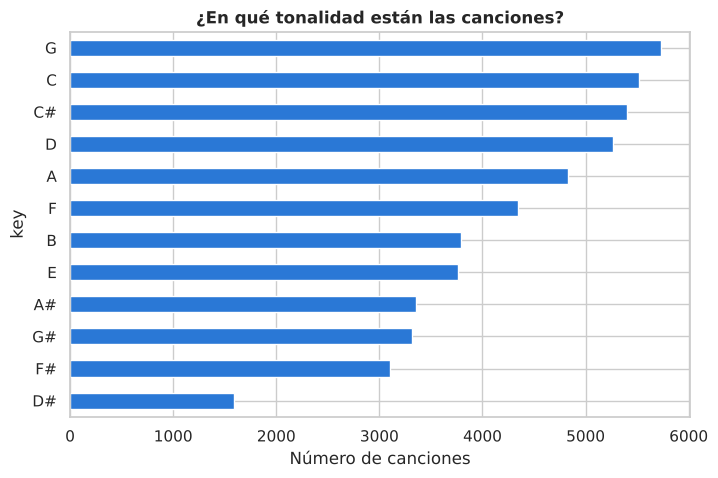

Moda de key: G  | moda de mode: Major


In [8]:
frec = df["key"].value_counts().to_frame("n_i")
frec["f_i_%"] = 100 * frec["n_i"] / frec["n_i"].sum()
ax = frec["n_i"].sort_values().plot.barh(color=AZUL, figsize=(8, 5))
ax.set_title("¿En qué tonalidad están las canciones?"); ax.set_xlabel("Número de canciones")
plt.show()
print("Moda de key:", df["key"].mode()[0], " | moda de mode:", df["mode"].mode()[0])

### Tabla de contingencia: ¿qué géneros usan más el modo **menor**?
En teoría musical se suele decir que el modo **mayor** suena "alegre" y el **menor**, "triste". Veamos qué géneros usan más cada uno.

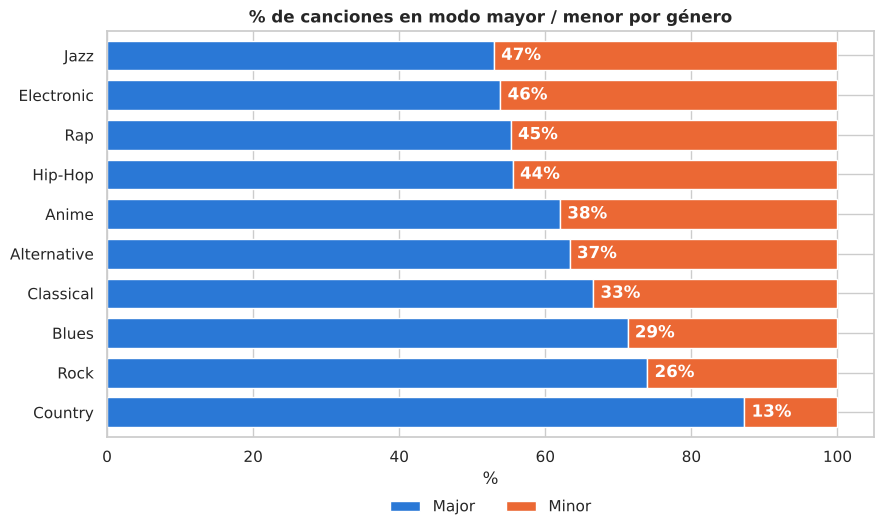

In [9]:
tabla_modo = pd.crosstab(df["music_genre"], df["mode"], normalize="index").mul(100).sort_values("Minor")
fig, ax = plt.subplots(figsize=(9, 5.5))
tabla_modo.plot.barh(stacked=True, color=[AZUL, NARANJA], width=0.75, edgecolor="white", ax=ax)
ax.set_title("% de canciones en modo mayor / menor por género")
ax.set_xlabel("%"); ax.set_ylabel("")
ax.legend(title="", frameon=False, ncol=2, loc="upper center", bbox_to_anchor=(0.5, -0.12))
for i, v in enumerate(tabla_modo["Minor"]):
    ax.text(100 - v + 1, i, f"{v:.0f}%", va="center", color="white", fontweight="bold")
plt.tight_layout(); plt.show()

🤔 **¿No es raro?** El **country** tiene fama de música triste (desamores, despedidas…) y resulta ser el género con **menos**
canciones en modo menor (13 %). ¿Está mal el dato, o está mal la idea de que "menor = triste"?

Spotify tiene otra variable pensada justo para eso: **`valence`** (de 0 a 1, cuánto de "positiva" o alegre suena una canción).
Si "modo menor = triste" fuera cierto, las canciones en modo menor deberían tener una valencia mucho más baja.

In [10]:
print("Valencia según el modo:")
print(df.groupby("mode")["valence"].agg(["mean", "median"]).round(3))
r_modo = (df["mode"] == "Minor").astype(int).corr(df["valence"])
print(f"\nCorrelación entre 'ser modo menor' (0/1) y valence: r = {r_modo:.3f}")

Valencia según el modo:
       mean  median
mode               
Major 0.461   0.453
Minor 0.448   0.439

Correlación entre 'ser modo menor' (0/1) y valence: r = -0.025


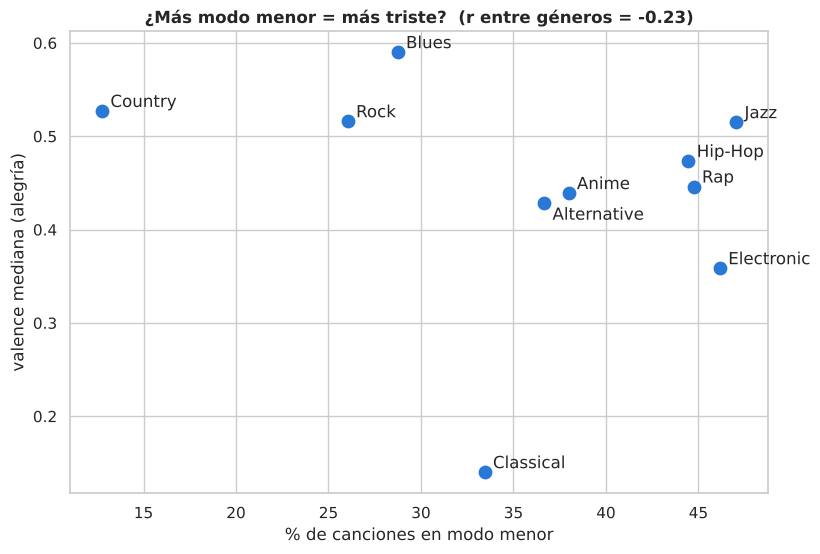

,% modo menor,valence mediana
music_genre,,
Classical,33.440,0.140
Electronic,46.160,0.358
Alternative,36.660,0.428
Anime,37.980,0.439
Rap,44.740,0.446
Hip-Hop,44.460,0.474
Jazz,47.040,0.515
Rock,26.040,0.516
Country,12.760,0.527


In [11]:
comp = pd.DataFrame({
    "% modo menor": 100 * (df["mode"] == "Minor").groupby(df["music_genre"]).mean(),
    "valence mediana": df.groupby("music_genre")["valence"].median(),
}).sort_values("valence mediana")
fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(comp["% modo menor"], comp["valence mediana"], s=80, color=AZUL)
for g, f in comp.iterrows():
    ax.annotate(g, (f["% modo menor"], f["valence mediana"]), xytext=(6, -12 if g == "Alternative" else 3), textcoords="offset points")
ax.set_xlabel("% de canciones en modo menor"); ax.set_ylabel("valence mediana (alegría)")
ax.set_title(f"¿Más modo menor = más triste?  (r entre géneros = {comp.corr().iloc[0, 1]:.2f})")
plt.show()
comp.round(3)

🎯 **Lección:** canción a canción, el modo y la "alegría" **casi no tienen relación** (r ≈ −0,03). Entre géneros sale algo más
(r ≈ −0,23), pero con solo 10 puntos y la clásica muy separada del resto: una relación débil y frágil. El country, con un 87 %
de modo mayor, es de hecho uno de los géneros con **más** valencia. Su tristeza está en las **letras**, y este dataset no mide las letras.

Una variable mide **lo que mide**, no lo que suponemos que mide. Antes de interpretar `mode` como "tristeza" hay que comprobarlo.
Y ojo: `valence` tampoco es "la verdad", es otra variable calculada por un algoritmo de Spotify a partir del audio.

## 4. Medidas de posición de una variable: **popularidad**

In [12]:
x = df["popularity"]
print(f"Media              : {x.mean():.2f}")
print(f"Mediana            : {x.median():.2f}")
print(f"Moda               : {x.mode().tolist()}")
print(f"Media recortada 5% : {stats.trim_mean(x, 0.05):.2f}")
print("Cuartiles:", x.quantile([.25, .5, .75]).tolist())
print("Percentil 99 (el 1 % más popular empieza en):", x.quantile(.99))

Media              : 44.22
Mediana            : 45.00
Moda               : [52.0]
Media recortada 5% : 44.57
Cuartiles: [34.0, 45.0, 56.0]
Percentil 99 (el 1 % más popular empieza en): 76.0


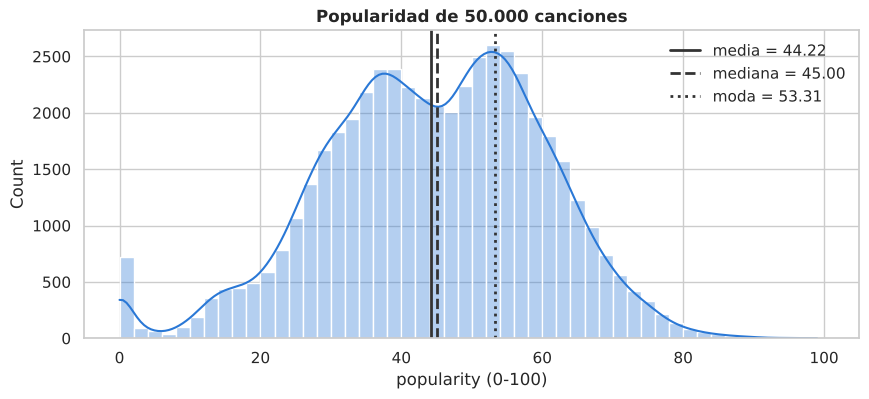

In [13]:
histograma_con_centros(df["popularity"], "Popularidad de 50.000 canciones", bins=range(0, 101, 2))
plt.xlabel("popularity (0-100)"); plt.show()

🤔 ¿Ves el **pico en 0**? ¿Son canciones que nadie escucha… o un dato faltante disfrazado? Ahora lo investigamos por género.

### 🚀 Retos de la sesión 1
1. ¿Cuántas canciones tienen `tempo` faltante en cada género? ¿Están repartidos por igual? (`df.groupby('music_genre')['tempo'].apply(lambda s: s.isna().sum())`)
2. Calcula la media, la mediana y la media recortada de `duracion_min`. ¿Cuál se parece más a la duración de una canción "normal"?
3. Calcula la tonalidad **moda** de cada género (`groupby(...)["key"].agg(lambda s: s.mode()[0])`).

---
✅ **Fin de la sesión 1.**

---
# 🕐 Sesión 2 de 3 · Formas, atípicos y comparación de géneros
**Objetivos:** asimetría, curtosis y bimodalidad, atípicos (Tukey frente a z), comparación de géneros con `groupby`.  
**Apartados:** 5 a 7 · **Duración orientativa:** 2 horas
> 💡 Si abres el notebook en una sesión nueva, ejecuta antes todas las celdas anteriores: menú *Entorno de ejecución → Ejecutar las celdas anteriores* (Ctrl+F8).

## 5. Dispersión y forma: todas las variables de un vistazo

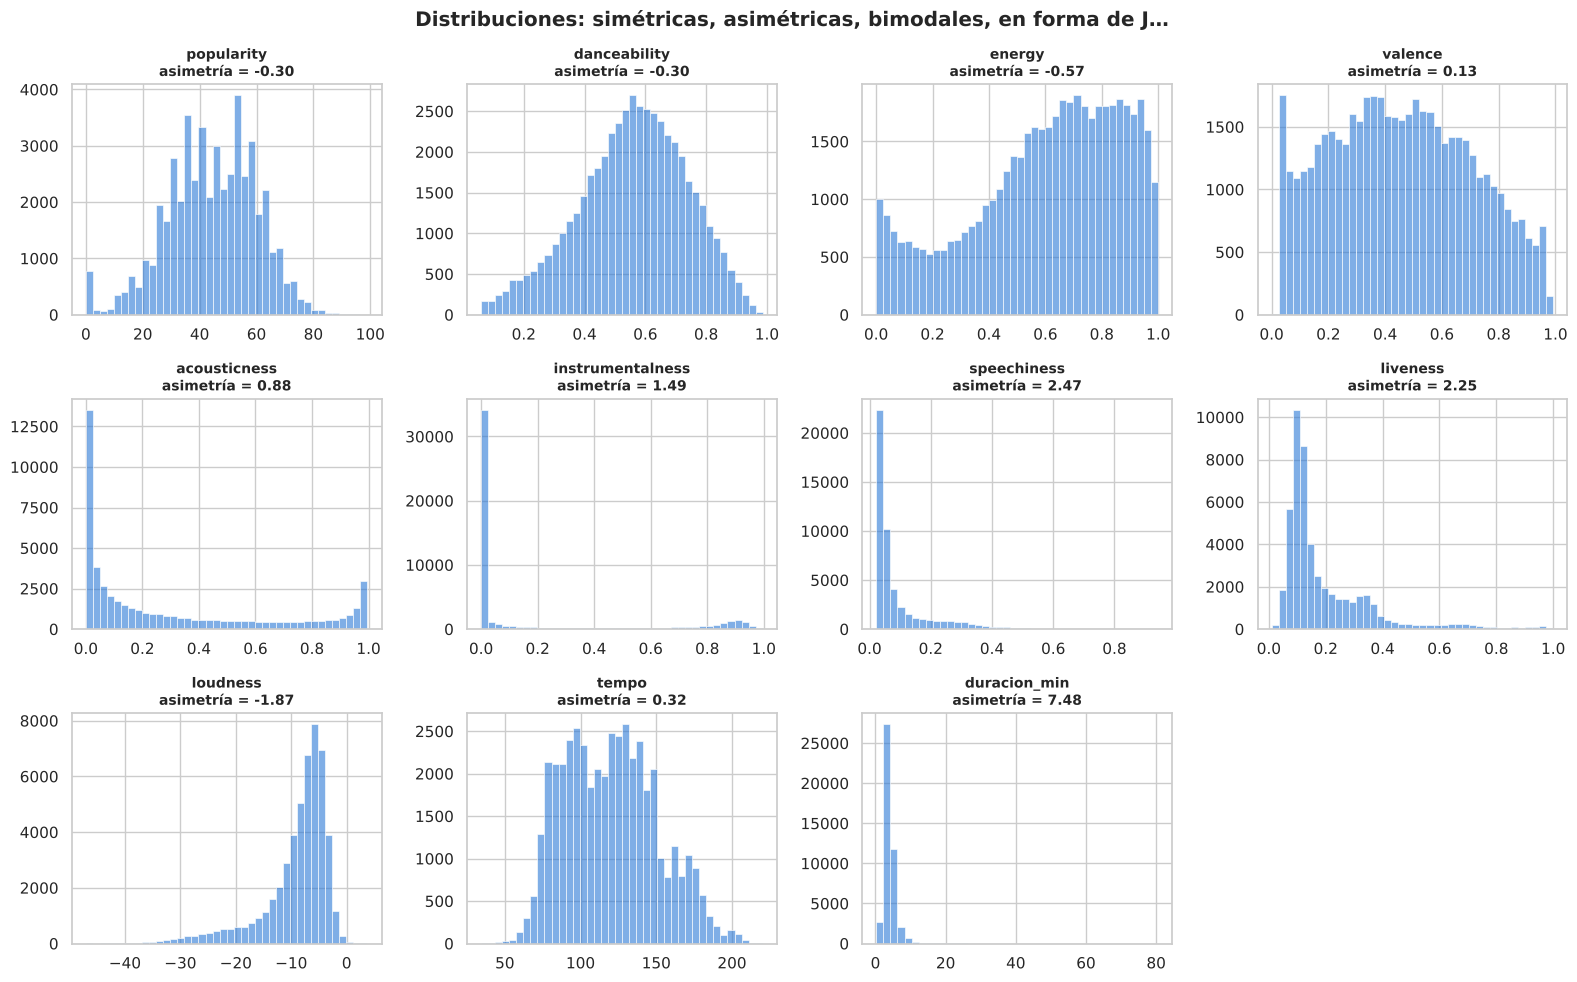

In [14]:
fig, axes = plt.subplots(3, 4, figsize=(16, 10))
for ax, v in zip(axes.flat, cuantitativas):
    sns.histplot(df[v], bins=40, ax=ax, color=AZUL, alpha=0.6)
    ax.set_title(f"{v}\nasimetría = {df[v].skew():.2f}", fontsize=10)
    ax.set_xlabel(""); ax.set_ylabel("")
axes.flat[-1].axis("off")
plt.suptitle("Distribuciones: simétricas, asimétricas, bimodales, en forma de J…", fontweight="bold")
plt.tight_layout(); plt.show()

🎯 **Zoo de formas:**
- `speechiness`, `liveness`, `instrumentalness`: asimetría **positiva** fuerte (en forma de J): casi todo cerca de 0 y una cola larga.
- `loudness`: asimetría **negativa** (cola a la izquierda: las canciones muy bajitas, clásica sobre todo).
- `instrumentalness` y `acousticness`: **bimodales** (dos picos). ¿Qué crees que hay en cada pico?
- `duracion_min`: asimetría enorme por unas pocas "canciones" larguísimas.

In [15]:
tabla = df[cuantitativas].apply(resumen).T
(tabla.style.format("{:,.3f}")
     .background_gradient(subset=["asimetria_Fisher"], cmap="RdBu_r", vmin=-3, vmax=3)
     .background_gradient(subset=["n_atipicos_Tukey"], cmap="Oranges"))

,n,media,mediana,moda,media_recortada_5%,min,Q1,Q3,max,rango,IQR,varianza,desv_tipica,CV_%,MAD,asimetria_Fisher,asimetria_Pearson,curtosis_exceso,n_atipicos_Tukey
popularity,"50,000.000",44.220,45.000,52.592,44.569,0.000,34.000,56.000,99.000,99.000,22.000,241.554,15.542,35.147,11.000,-0.305,-0.150,0.013,713.000
danceability,"50,000.000",0.558,0.568,0.575,0.562,0.060,0.442,0.687,0.986,0.926,0.245,0.032,0.179,31.999,0.122,-0.300,-0.164,-0.301,104.000
energy,"50,000.000",0.600,0.643,0.715,0.610,0.001,0.433,0.815,0.999,0.998,0.382,0.070,0.265,44.111,0.187,-0.570,-0.490,-0.594,0.000
valence,"50,000.000",0.456,0.448,0.368,0.453,0.000,0.257,0.648,0.992,0.992,0.391,0.061,0.247,54.161,0.195,0.132,0.100,-0.932,0.000
acousticness,"50,000.000",0.306,0.144,0.034,0.285,0.000,0.020,0.552,0.996,0.996,0.532,0.117,0.341,111.410,0.141,0.882,1.427,-0.722,0.000
instrumentalness,"50,000.000",0.182,0.000,0.030,0.150,0.000,0.000,0.155,0.996,0.996,0.155,0.106,0.325,179.189,0.000,1.487,1.673,0.457,"10,453.000"
speechiness,"50,000.000",0.094,0.049,0.052,0.079,0.022,0.036,0.099,0.942,0.920,0.062,0.010,0.101,108.320,0.017,2.475,1.322,7.414,"6,970.000"
liveness,"50,000.000",0.194,0.126,0.102,0.172,0.010,0.097,0.244,1.000,0.990,0.147,0.026,0.162,83.363,0.044,2.249,1.260,5.710,"3,238.000"
loudness,"50,000.000",-9.134,-7.277,-6.358,-8.463,-47.046,-10.860,-5.173,3.744,50.790,5.687,37.982,6.163,67.475,2.544,-1.871,-0.904,4.005,"4,012.000"
tempo,"45,020.000",119.953,119.879,94.889,119.148,34.347,94.941,140.471,220.276,185.929,45.530,938.914,30.642,25.545,23.828,0.323,0.007,-0.563,26.000


🤔 Comparad `media` y `mediana` en `instrumentalness`: 0.18 frente a casi 0. **¿Qué medida describe mejor una canción "típica"?**
Y en `speechiness`, ¿qué os dice que la `MAD` sea tan pequeña comparada con la desviación típica?

## 6. Atípicos: ¿canciones de 80 minutos?

In [16]:
li, ls = limites_tukey(df["duracion_min"])
atip = df[df["duracion_min"] > ls]
print(f"Vallas de Tukey: [{li:.2f}, {ls:.2f}] minutos -> {len(atip)} atípicos por arriba ({100*len(atip)/df['duracion_min'].notna().sum():.1f} %)")
df.nlargest(8, "duracion_min")[["artist_name", "track_name", "music_genre", "duracion_min"]]

Vallas de Tukey: [1.04, 6.72] minutos -> 2440 atípicos por arriba (5.4 %)


,artist_name,track_name,music_genre,duracion_min
1410,Excision,Lost Lands 2017 Mix,Electronic,80.510
2133,Bonobo,Late Night Tales: Bonobo,Electronic,74.967
3759,Bassnectar,Mixtape 13,Electronic,71.267
43868,Sultan Khan,Rag Bhupali,Classical,53.257
4593,NaN,45:33:00,Electronic,46.082
42075,Imrat Khan,Rag Miya Ki Todi,Classical,38.233
33508,The Allman Brothers Band,Mountain Jam (Theme From “First There Is A Mou...,Blues,33.655
42337,Gustav Mahler,Symphony No. 3 in D Minor / Pt. 1: 1. Kräftig....,Classical,32.263


Los récords son **mixes y mixtapes**, no canciones. Atípico ≠ error, pero aquí sí cabe preguntarse si deben estar en el análisis.

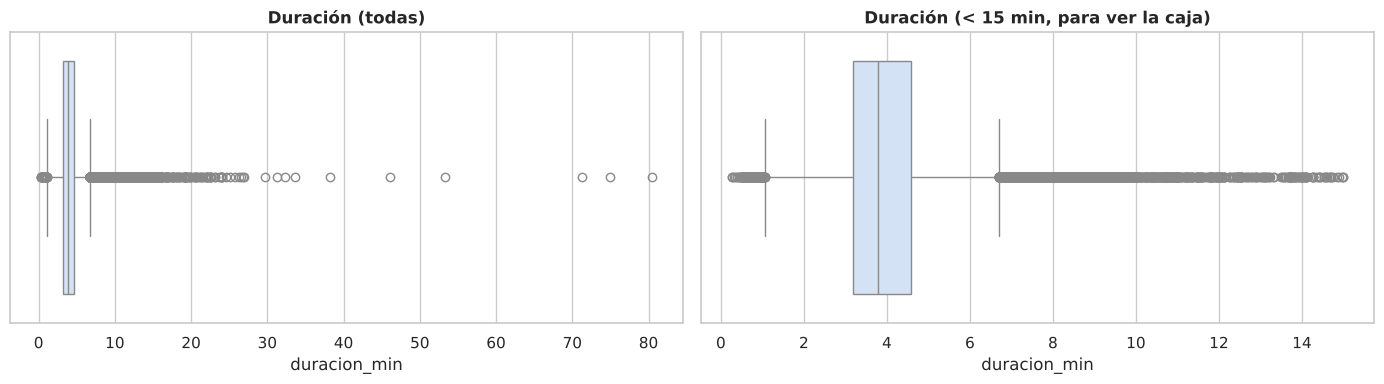

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.boxplot(x=df["duracion_min"], ax=axes[0], color="#cde2fb")
axes[0].set_title("Duración (todas)")
sns.boxplot(x=df.loc[df["duracion_min"] < 15, "duracion_min"], ax=axes[1], color="#cde2fb")
axes[1].set_title("Duración (< 15 min, para ver la caja)")
plt.tight_layout(); plt.show()

### Tukey vs. z-score
Con colas tan largas, la desviación típica se "infla" por los propios atípicos y la regla |z| > 3 detecta **menos**.

In [18]:
comparacion = []
for v in ["duracion_min", "speechiness", "liveness", "loudness", "tempo"]:
    s = df[v].dropna()
    li, ls = limites_tukey(s)
    z = (s - s.mean()) / s.std()
    comparacion.append({"variable": v, "Tukey_1.5IQR": ((s < li) | (s > ls)).sum(), "|z|>3": (z.abs() > 3).sum()})
pd.DataFrame(comparacion).set_index("variable")

,Tukey_1.5IQR,|z|>3
variable,,
duracion_min,2694,582
speechiness,6970,1118
liveness,3238,1435
loudness,4012,1115
tempo,26,15


## 7. 🏆 Comparación por géneros con `groupby`

In [19]:
pop = (df.groupby("music_genre")["popularity"]
         .agg(media="mean", mediana="median", desv="std",
              Q1=lambda s: s.quantile(.25), Q3=lambda s: s.quantile(.75),
              ceros=lambda s: (s == 0).sum(), asimetria="skew")
         .sort_values("mediana", ascending=False))
pop["media_menos_mediana"] = pop["media"] - pop["mediana"]
pop.style.format("{:.2f}").background_gradient(subset=["mediana"], cmap="Blues").background_gradient(subset=["ceros"], cmap="Oranges")

,media,mediana,desv,Q1,Q3,ceros,asimetria,media_menos_mediana
music_genre,,,,,,,,
Rock,59.64,59.00,7.36,55.00,64.00,1.00,-0.09,0.64
Rap,60.50,59.00,8.16,55.00,65.00,0.00,0.54,1.50
Hip-Hop,58.40,57.00,8.30,52.00,63.00,0.00,0.69,1.40
Alternative,50.22,49.00,7.66,45.00,55.00,5.00,0.02,1.22
Country,46.01,44.00,9.77,39.00,52.00,41.00,-0.14,2.01
Jazz,40.93,40.00,9.52,36.00,46.00,27.00,-0.66,0.93
Electronic,38.11,37.00,9.72,31.00,44.00,27.00,0.34,1.11
Blues,34.80,33.00,9.72,28.75,39.00,31.00,0.61,1.80
Classical,29.32,32.00,14.10,25.00,38.00,541.00,-0.74,-2.68


🔍 **¡La clásica es el único género con media < mediana!** Tiene más de 500 canciones con popularidad 0 que tiran de la media hacia abajo
(asimetría negativa). Una sola tabla de `groupby` y ya hemos encontrado algo raro en los datos.

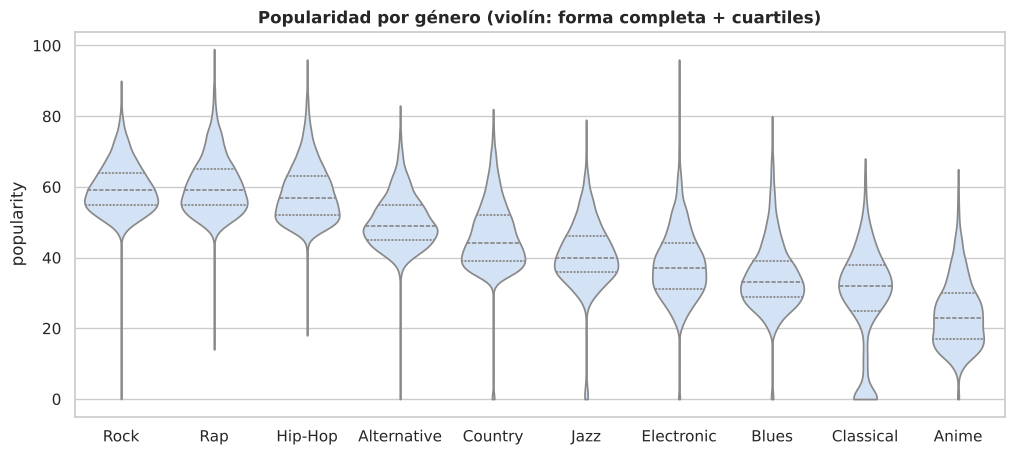

In [20]:
orden = df.groupby("music_genre")["popularity"].median().sort_values(ascending=False).index
fig, ax = plt.subplots(figsize=(12, 5))
sns.violinplot(data=df, x="music_genre", y="popularity", order=orden, color="#cde2fb", inner="quart", cut=0, ax=ax)
ax.set_title("Popularidad por género (violín: forma completa + cuartiles)"); ax.set_xlabel("")
plt.show()

### Perfil sonoro de cada género (medianas)

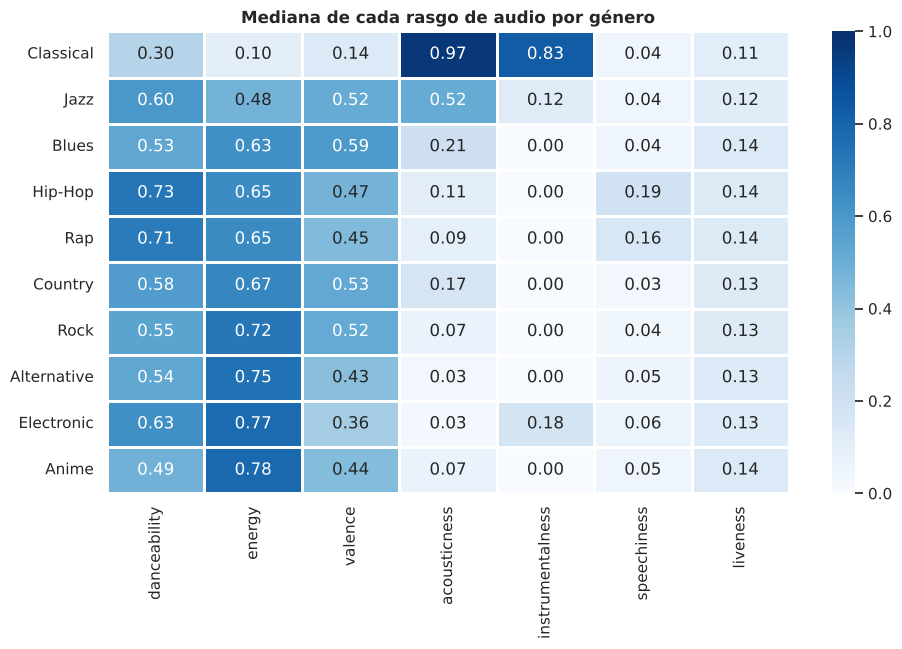

In [21]:
rasgos = ["danceability", "energy", "valence", "acousticness", "instrumentalness", "speechiness", "liveness"]
perfil = df.groupby("music_genre")[rasgos].median().sort_values("energy")
plt.figure(figsize=(11, 6))
sns.heatmap(perfil, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, linewidths=2, linecolor="white")
plt.title("Mediana de cada rasgo de audio por género"); plt.ylabel(""); plt.show()

🤔 Con esta tabla, ¿podrías **adivinar el género** de una canción sabiendo solo su `energy` y su `instrumentalness`? (Esto, en segundo, se llamará *clasificación*.)

### ¿Rap y Hip-Hop son el mismo género?

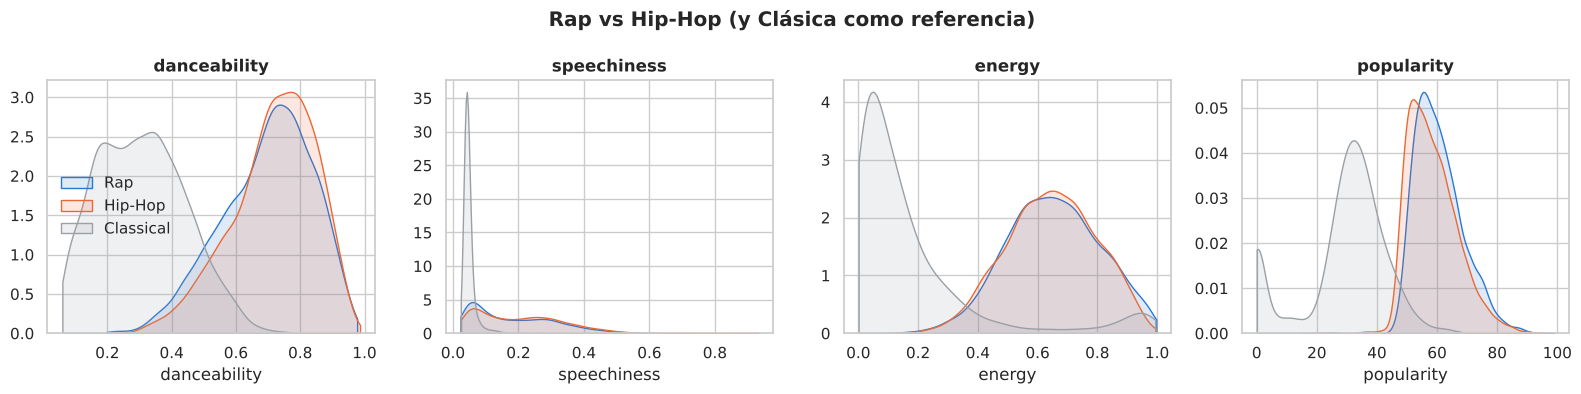

music_genre              Hip-Hop    Rap
danceability     mean      0.717  0.697
                 median    0.733  0.714
energy           mean      0.644  0.651
                 median    0.648  0.649
valence          mean      0.475  0.455
                 median    0.474  0.446
acousticness     mean      0.179  0.169
                 median    0.109  0.094
instrumentalness mean      0.011  0.009
                 median    0.000  0.000
speechiness      mean      0.207  0.187
                 median    0.192  0.158
liveness         mean      0.201  0.198
                 median    0.136  0.135
popularity       mean     58.400 60.497
                 median   57.000 59.000

In [22]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, v in zip(axes, ["danceability", "speechiness", "energy", "popularity"]):
    for g, c in [("Rap", AZUL), ("Hip-Hop", NARANJA), ("Classical", "#9aa0a6")]:
        sns.kdeplot(df.loc[df["music_genre"] == g, v], ax=ax, label=g, color=c, fill=True, alpha=0.15, cut=0)
    ax.set_title(v); ax.set_ylabel("")
axes[0].legend(frameon=False)
plt.suptitle("Rap vs Hip-Hop (y Clásica como referencia)", fontweight="bold")
plt.tight_layout(); plt.show()
df[df["music_genre"].isin(["Rap", "Hip-Hop"])].groupby("music_genre")[rasgos + ["popularity"]].agg(["mean", "median"]).round(3).T

### ¿Qué género es más **homogéneo**? Dispersión por grupo

In [23]:
disp = df.groupby("music_genre")[["danceability", "energy", "tempo"]].agg(lambda s: 100 * s.std() / s.mean()).round(1)
disp.columns = [f"CV_{c}_%" for c in disp.columns]
disp.sort_values("CV_energy_%").style.background_gradient(cmap="Oranges")

,CV_danceability_%,CV_energy_%,CV_tempo_%
music_genre,,,
Hip-Hop,18.200000,23.400000,24.900000
Rap,20.100000,24.000000,24.300000
Electronic,23.700000,25.400000,21.000000
Alternative,27.700000,29.100000,24.700000
Rock,24.900000,29.200000,23.600000
Country,18.900000,31.200000,24.300000
Blues,27.300000,37.400000,25.000000
Anime,31.600000,45.200000,26.100000
Jazz,27.300000,50.400000,26.500000


### 🚀 Retos de la sesión 2
1. ¿Qué **artista** con al menos 20 canciones tiene la mayor popularidad mediana? (`groupby("artist_name")` + `filter` o `agg` con `size`).
2. Repite la tabla de popularidad por género **quitando las popularidades 0**. ¿Cambia el ranking? ¿Cambia la media de la clásica?
3. Crea una variable `tempo_cat` con `pd.cut` (lento < 90, medio 90-130, rápido > 130) y cruza con el género. ¿Qué género es el más rápido?
4. Busca la canción más "anómala" del dataset: la que tenga la mayor suma de |z| en todos los rasgos.

---
✅ **Fin de la sesión 2.**

---
# 🕐 Sesión 3 de 3 · Dos variables: correlación y regresión
**Objetivos:** correlación, regresión lineal y exponencial, dominio de los modelos, la trampa del R² en logaritmos, duplicados.  
**Apartados:** 8 a 10 · **Duración orientativa:** 2 horas
> 💡 Si abres el notebook en una sesión nueva, ejecuta antes todas las celdas anteriores: menú *Entorno de ejecución → Ejecutar las celdas anteriores* (Ctrl+F8).

## 8. Dos variables cuantitativas: energía, volumen y acústica

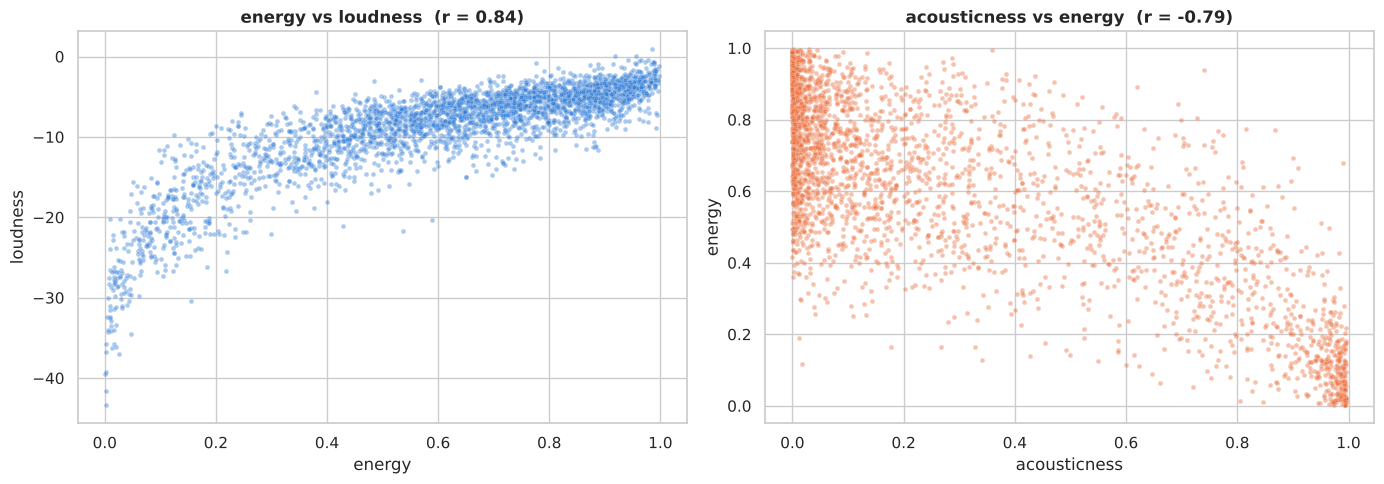

In [24]:
muestra = df.sample(3000, random_state=1)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(data=muestra, x="energy", y="loudness", s=12, alpha=0.4, color=AZUL, ax=axes[0])
axes[0].set_title(f"energy vs loudness  (r = {df['energy'].corr(df['loudness']):.2f})")
sns.scatterplot(data=muestra, x="acousticness", y="energy", s=12, alpha=0.4, color=NARANJA, ax=axes[1])
axes[1].set_title(f"acousticness vs energy  (r = {df['acousticness'].corr(df['energy']):.2f})")
plt.tight_layout(); plt.show()

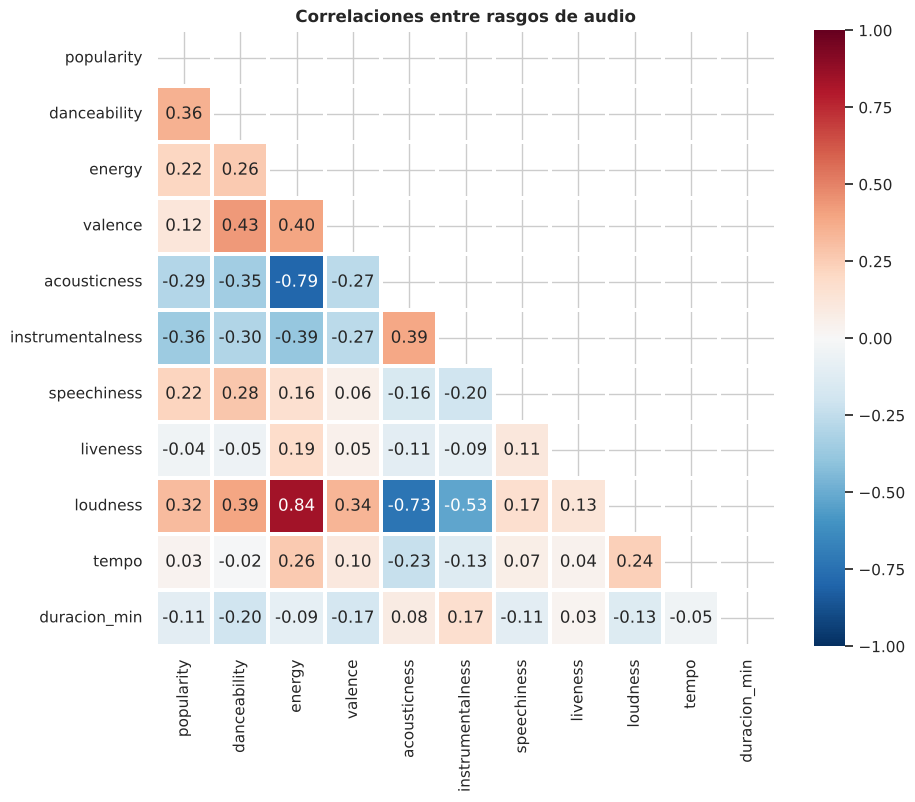

In [25]:
corr = df[cuantitativas].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
plt.figure(figsize=(10, 8))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, linewidths=1.5, linecolor="white")
plt.title("Correlaciones entre rasgos de audio"); plt.show()

## 9. 📈 Regresión: ¿se puede predecir la energía de una canción por su volumen?
Tres modelos ajustados por mínimos cuadrados ($x$ = `loudness` en dB, $y$ = `energy`):

| Modelo | Ecuación | Linealización | Requisitos |
|---|---|---|---|
| Lineal | $y = a + b\,x$ | — | ninguno |
| Potencial | $y = a\,x^{b}$ | $\ln y = \ln a + b\,\ln x$ | $x > 0$ e $y > 0$ |
| Exponencial | $y = a\,e^{b x}$ | $\ln y = \ln a + b\,x$ | $y > 0$ |

In [26]:
print("loudness: mínimo", df["loudness"].min(), " máximo", df["loudness"].max())
print("energy  : mínimo", df["energy"].min(), " máximo", df["energy"].max())

loudness: mínimo -47.04600000000001  máximo 3.744
energy  : mínimo 0.000792  máximo 0.999


🤔 El volumen en decibelios es **casi siempre negativo** (0 dB es el máximo digital). No existe $\ln x$ para $x \le 0$, así que
**el modelo potencial no se puede ajustar**. Antes de elegir un modelo, hay que mirar el **dominio** de las variables.

In [27]:
tabla_reg, modelos = regresiones(df["loudness"], df["energy"])
tabla_reg

,ecuación,a,b,R2 (escala del ajuste),R2 (escala original)
modelo,,,,,
lineal,y = 0.9285 + 0.03599·x,0.928,0.036,0.703,0.703
potencial,no aplicable: necesita x > 0 e y > 0,NaN,NaN,NaN,NaN
exponencial,y = 1.566·e^(0.1286·x),1.566,0.129,0.818,0.637


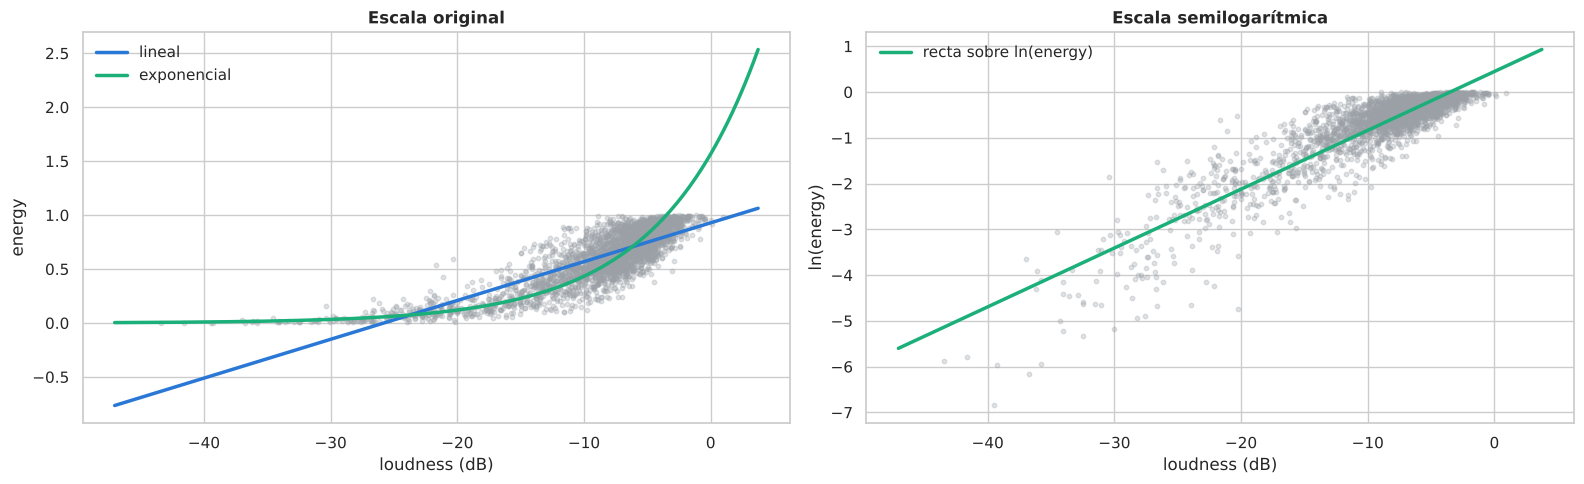

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
dibujar_regresiones(df["loudness"], df["energy"], modelos, ax=axes[0],
                    xlabel="loudness (dB)", ylabel="energy", titulo="Escala original")
m = df[["loudness", "energy"]].dropna().sample(3000, random_state=1)
axes[1].scatter(m["loudness"], np.log(m["energy"]), s=10, alpha=0.3, color="#9aa0a6")
A, B = recta_minimos_cuadrados(df["loudness"], np.log(df["energy"]))
xs = np.linspace(df["loudness"].min(), df["loudness"].max(), 100)
axes[1].plot(xs, A + B * xs, color=VERDE, lw=2.5, label="recta sobre ln(energy)")
axes[1].set_xlabel("loudness (dB)"); axes[1].set_ylabel("ln(energy)"); axes[1].set_title("Escala semilogarítmica")
axes[1].legend(frameon=False)
plt.tight_layout(); plt.show()

### ⚠️ La trampa del $R^2$ en escala logarítmica
Mira las dos columnas de $R^2$ de la tabla:
- En **su escala** (recta sobre $\ln y$), el exponencial tiene un $R^2$ **mayor** que el lineal.
- En la **escala original** (predicción de la energía de verdad), el exponencial es **peor** que el lineal.

No son comparables: el primero mide qué tal se ajusta una recta a $\ln(\text{energy})$, y el segundo qué tal se predice `energy`.
Para elegir entre modelos, **siempre en la escala original**. El logaritmo "estira" los valores pequeños de energía
(canciones muy tranquilas) y el ajuste se esfuerza en acertar sobre todo ahí.

In [29]:
print(f"Canción a -5 dB (pop actual) : lineal {modelos['lineal'](-5):.3f} | exponencial {modelos['exponencial'](-5):.3f}")
print(f"Canción a -30 dB (clásica)   : lineal {modelos['lineal'](-30):.3f} | exponencial {modelos['exponencial'](-30):.3f}")
print(f"Canción a -45 dB             : lineal {modelos['lineal'](-45):.3f} | exponencial {modelos['exponencial'](-45):.3f}")

Canción a -5 dB (pop actual) : lineal 0.749 | exponencial 0.824
Canción a -30 dB (clásica)   : lineal -0.151 | exponencial 0.033
Canción a -45 dB             : lineal -0.691 | exponencial 0.005


🤔 ¿Qué modelo predice una energía **negativa** para canciones muy bajitas? La energía va de 0 a 1… **la recta no sabe que hay un suelo**.
El exponencial nunca baja de 0… pero mira el gráfico: para canciones muy fuertes (cerca de 0 dB) predice energías **mayores que 1**,
y la energía tiene un **techo**. Ninguno de los dos modelos respeta los dos límites (en cursos posteriores veréis modelos que sí).
Moraleja: un modelo puede tener buen $R^2$ y aun así decir cosas imposibles.

### ¿Es igual en todos los géneros? Regresión por grupos

In [30]:
por_genero = []
for genero, g in df.groupby("music_genre"):
    t, _ = regresiones(g["loudness"], g["energy"])
    por_genero.append({"genero": genero, "n": len(g),
                       "pendiente_lineal": t.loc["lineal", "b"],
                       "R2_lineal": t.loc["lineal", "R2 (escala original)"],
                       "R2_exponencial": t.loc["exponencial", "R2 (escala original)"]})
pd.DataFrame(por_genero).set_index("genero").sort_values("R2_lineal", ascending=False).round(3)

,n,pendiente_lineal,R2_lineal,R2_exponencial
genero,,,,
Anime,5000,0.042,0.755,0.715
Classical,5000,0.024,0.650,0.798
Jazz,5000,0.040,0.613,0.605
Alternative,5000,0.057,0.581,0.573
Country,5000,0.047,0.580,0.590
Electronic,5000,0.039,0.571,0.548
Rock,5000,0.046,0.570,0.560
Blues,5000,0.044,0.552,0.505
Rap,5000,0.045,0.479,0.487


🤔 En casi todos los géneros gana la recta… salvo en **Classical**, donde el exponencial es claramente mejor. ¿Por qué?
(pista: ¿en qué género hay muchas canciones con muy poco volumen y energía casi 0? Vuelve al gráfico de escala original.)

## 10. Calidad de datos: duplicados
Una misma canción puede aparecer **varias veces** (y en géneros distintos). ¿Cuántas?

In [31]:
claves = df.dropna(subset=["artist_name"])
dup = claves[claves.duplicated(["artist_name", "track_name"], keep=False)]
print("Filas con canción repetida:", len(dup))
generos_por_cancion = dup.groupby(["artist_name", "track_name"])["music_genre"].nunique()
print("Canciones repetidas en MÁS DE UN género:", (generos_por_cancion > 1).sum())
pd.crosstab(dup["music_genre"], "repeticiones").sort_values("repeticiones", ascending=False).T

Filas con canción repetida: 7408
Canciones repetidas en MÁS DE UN género: 3606


music_genre,Rap,Hip-Hop,Rock,Alternative,Country,Blues,Jazz,Electronic,Classical,Anime
col_0,,,,,,,,,,
repeticiones,1884,1769,1186,1110,450,347,347,209,64,42


🤔 Si una canción está a la vez en *Rap* y en *Hip-Hop*, ¿qué hace eso con las comparaciones del apartado 7?

### 🚀 Retos de la sesión 3
1. Ajusta los tres modelos para `acousticness` frente a `energy`. ¿Por qué falla el potencial? (pista: busca valores exactamente 0)
2. Repite la regresión `energy` ~ `loudness` **solo para Classical** y dibuja los dos modelos con `dibujar_regresiones`. ¿Por qué ahí gana el exponencial?
3. ¿Qué pareja de rasgos de audio tiene la correlación negativa más fuerte? Ajusta su recta e interpreta la pendiente.

---
🏁 **Fin del notebook.**